# 07 · Feature extraction

Turn completed audio windows into causal 40-band log-Mel features.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
import wave
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

### Math for the next code block — input amplitude

PCM16 integer samples become full-scale floating-point samples through $x=q/32768$. A mono recording is therefore a vector $x\in\mathbb{R}^{N}$.

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as wav:
        meta = {
            "sample_rate": wav.getframerate(), 
            "channels": wav.getnchannels(),
            "sample_width": wav.getsampwidth(), 
            "frames": wav.getnframes()
        }
        if wav.getcomptype() != "NONE" or meta["sample_width"] != 2:
            raise ValueError("Only uncompressed PCM16 WAV is supported")
        pcm = wav.readframes(meta["frames"])
    if not meta["frames"] or len(pcm) != meta["frames"] * meta["channels"] * 2:
        raise ValueError("Empty or truncated PCM")
    audio = np.frombuffer(pcm, dtype="<i2").reshape(-1, meta["channels"]).astype(np.float32) / 32768
    meta["pcm_sha256"] = hashlib.sha256(pcm).hexdigest()
    return audio, meta

def write_audio(path, audio, rate):
    path.parent.mkdir(parents=True, exist_ok=True)
    pcm = np.clip(np.rint(np.asarray(audio) * 32768), -32768, 32767).astype("<i2")
    with wave.open(str(path), "wb") as wav:
        wav.setnchannels(1); wav.setsampwidth(2); wav.setframerate(rate)
        wav.writeframes(pcm.tobytes())

## Define the feature transform

Frames use a periodic Hann window, power spectrum, triangular HTK-Mel filters, and natural-log compression.

### Math for the next code block — causal log-Mel features

Let window length $W=400$, hop $H=160$, FFT size $K=512$, and Mel bands $M=40$.

1. **Causal frames:** frame $t$ contains

   $$x_t[n]=x[tH+n],\qquad 0\le n<W.$$

2. **Periodic Hann window:**

   $$w[n]=\tfrac12-\tfrac12\cos\!\left(\frac{2\pi n}{W}\right).$$

3. **DFT and power:**

   $$X_t[k]=\sum_{n=0}^{W-1}x_t[n]w[n]e^{-j2\pi kn/K},\qquad
   P_t[k]=\frac{|X_t[k]|^2}{K}.$$

4. **HTK Mel scale and inverse:**

   $$m(f)=2595\log_{10}(1+f/700),\qquad f(m)=700(10^{m/2595}-1).$$

5. **Triangular filter bank:** for filter $r$ with edges $(e_{r-1},e_r,e_{r+1})$,

   $$H_r(f)=\max\!\left(0,\min\!\left(\frac{f-e_{r-1}}{e_r-e_{r-1}},\frac{e_{r+1}-f}{e_{r+1}-e_r}\right)\right).$$

6. **Log-Mel output:**

   $$F[t,r]=\ln\!\left(\max\!\left(\sum_kP_t[k]H_r(f_k),10^{-10}\right)\right).$$

For one recording, $F$ has shape $T\times40$.

In [4]:
class LogMel:
    def __init__(self,cfg):
        self.cfg=cfg

        # Window
        self.window=np.hanning(cfg["window_samples"]+1)[:-1].astype(np.float32)
        
        # Hz to Mel
        hz_to_mel=lambda f:2595*np.log10(1+np.asarray(f)/700)
        
        # Mel to Hz
        mel_to_hz=lambda m:700*(10**(np.asarray(m)/2595)-1)
        
        edges=mel_to_hz(
            np.linspace(
                hz_to_mel(cfg["mel_min_hz"]),
                hz_to_mel(cfg["mel_max_hz"]),
                cfg["mel_bands"]+2
            )
        )

        # Frequency
        frequency=np.fft.rfftfreq(
            cfg["fft_size"],
            1/cfg["sample_rate"]
        )

        # Left
        left=(frequency[None,:]-edges[:-2,None])/(edges[1:-1,None]-edges[:-2,None])
        # Right
        right=(edges[2:,None]-frequency[None,:])/(edges[2:,None]-edges[1:-1,None])

        # Filters
        self.filters=np.maximum(0,np.minimum(left,right)).astype(np.float32)
        
        if np.any(self.filters.sum(axis=1)==0): 
            raise ValueError("Empty Mel filter")

    def frames(self,frames):
        # FFT
        spectrum=np.fft.rfft(frames*self.window,n=self.cfg["fft_size"],axis=-1)
        power=np.abs(spectrum)**2/self.cfg["fft_size"]
        return np.log(np.maximum(power@self.filters.T,self.cfg["log_floor"])).astype(np.float32)

    def __call__(self,signal):
        size,hop=self.cfg["window_samples"],self.cfg["hop_samples"]
        if len(signal)<size: return np.empty((0,self.cfg["mel_bands"]),dtype=np.float32)
        frames=np.lib.stride_tricks.sliding_window_view(signal,size)[::hop]
        return self.frames(frames)

### Math for the next code block — streaming buffer

After appending a microphone chunk to buffer $B$, the number of complete frames is

$$T_B=\max\!\left(0,1+\left\lfloor\frac{|B|-W}{H}\right\rfloor\right).$$

Emit those $T_B$ frames and retain the suffix beginning at sample $T_BH$. No right padding is added, so every emitted feature depends only on audio already received.

In [5]:
class StreamingLogMel:
    # Emit completed windows only; retain overlap without future padding.
    def __init__(self,extractor):
        self.extractor=extractor
        self.pending=np.empty(0,dtype=np.float32)
    
    def push(self,chunk):
        self.pending=np.concatenate(
            (self.pending,np.asarray(chunk,dtype=np.float32))
        )
        features=self.extractor(self.pending)
        self.pending=self.pending[len(features)*self.extractor.cfg["hop_samples"]:]
        return features

## Extract every recording

The first frame becomes available after 25 ms. Later frames advance by 10 ms. An incomplete trailing window is discarded at end of file.

### Math for the next code block — frame count and timestamps

For a recording with $N\ge W$ samples,

$$T=1+\left\lfloor\frac{N-W}{H}\right\rfloor.$$

Because a frame is emitted only when its window is complete, its right-edge timestamp is

$$\tau_t=\frac{W+tH}{f_s},\qquad t=0,\ldots,T-1.$$

With the current parameters, $\tau_0=25$ ms and consecutive timestamps differ by 10 ms.

In [6]:
extractor=LogMel(cfg)
rows=[]
for record in load_manifest("06_augmented.jsonl"):
    audio,_=read_audio(root/record["audio_path"])
    values=extractor(audio[:,0])
    if not len(values): 
        raise ValueError(f"No complete frame: {record['id']}")
    path=out/"07_features"/record["split"]/f"{record['id']}.npy"
    path.parent.mkdir(parents=True,exist_ok=True)
    np.save(path,values)
    rows.append({**record,"feature_path":str(path.relative_to(root)),"feature_frames":len(values),
                 "first_frame_end_seconds":cfg["window_samples"]/cfg["sample_rate"],
                 "feature_hop_seconds":cfg["hop_samples"]/cfg["sample_rate"]})
save_manifest("07_features.jsonl",rows)

In [7]:
display({"rows":len(rows),"bands":cfg["mel_bands"],"minimum_frames":min(r["feature_frames"] for r in rows),
         "maximum_frames":max(r["feature_frames"] for r in rows),"first_frame_ms":1000*rows[0]["first_frame_end_seconds"]})

{'rows': 14330,
 'bands': 40,
 'minimum_frames': 41,
 'maximum_frames': 98,
 'first_frame_ms': 25.0}

## Waveform and spectral evidence

In [8]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

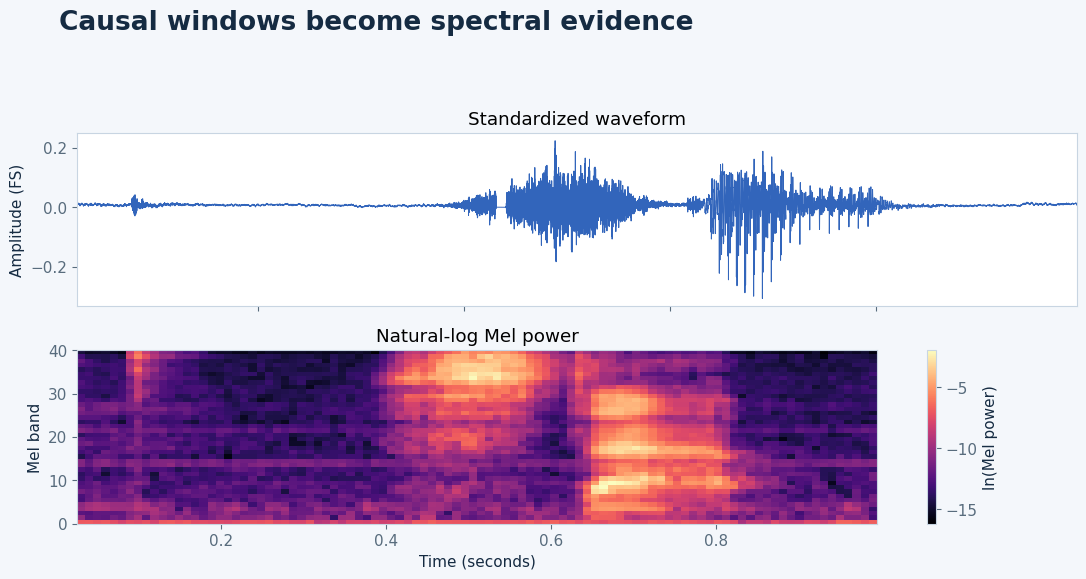

In [9]:
example=next(r for r in rows if r["is_keyword"] and r["split"]=="train" and not r["is_augmented"])
audio,_=read_audio(root/example["audio_path"]); values=np.load(root/example["feature_path"])
start=cfg["window_samples"]/cfg["sample_rate"]; end=start+(len(values)-1)*cfg["hop_samples"]/cfg["sample_rate"]
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].plot(np.arange(len(audio))/cfg["sample_rate"],audio[:,0],lw=.7,color=BLUE); axes[0].set(ylabel="Amplitude (FS)",title="Standardized waveform")
image=axes[1].imshow(values.T,origin="lower",aspect="auto",extent=[start,end,0,cfg["mel_bands"]],cmap="magma")
axes[1].set(xlabel="Time (seconds)",ylabel="Mel band",title="Natural-log Mel power"); fig.colorbar(image,ax=axes[1],label="ln(Mel power)")
fig.suptitle("Causal windows become spectral evidence",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.91)); finish_figure(fig,"07_log_mel")

Continue with [08 · Feature normalization](08_feature_normalization.ipynb).